# E-Commerce Delivery Analysis
## Dataset: `E_Commerce.csv`

This notebook analyzes the uploaded E-Commerce dataset. The accompanying Description document defines `Reached.on.Time_Y.N` as the target:
- `1` = product **did not** reach on time
- `0` = product **reached** on time

The notebook includes data loading, inspection, cleaning checks, exploratory analysis, visualizations, and an optional machine-learning baseline.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Optional: install seaborn if needed with: %pip install seaborn
try:
    import seaborn as sns
    sns.set_theme(style="whitegrid")
except ImportError:
    sns = None

from pathlib import Path


## 2. Load the CSV file
Keep `E_Commerce (1).csv` in the same folder as this notebook, or update `CSV_PATH`.

In [2]:
CSV_PATH = Path("E_Commerce (1).csv")

if not CSV_PATH.exists():
    # Also check the common original filename
    alternative = Path("E_Commerce.csv")
    if alternative.exists():
        CSV_PATH = alternative
    else:
        raise FileNotFoundError(
            "CSV file not found. Place 'E_Commerce (1).csv' or 'E_Commerce.csv' "
            "in the same folder as this notebook, or update CSV_PATH."
        )

df = pd.read_csv(CSV_PATH)
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (10999, 12)


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


## 3. Understand the data

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nSummary statistics:")
display(df.describe(include="all").T)


Column names:
['ID', 'Warehouse_block', 'Mode_of_Shipment', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Gender', 'Discount_offered', 'Weight_in_gms', 'Reached.on.Time_Y.N']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   10999 non-null  int64 
 1   Warehouse_block      10999 non-null  object
 2   Mode_of_Shipment     10999 non-null  object
 3   Customer_care_calls  10999 non-null  int64 
 4   Customer_rating      10999 non-null  int64 
 5   Cost_of_the_Product  10999 non-null  int64 
 6   Prior_purchases      10999 non-null  int64 
 7   Product_importance   10999 non-null  object
 8   Gender               10999 non-null  object
 9   Discount_offered     10999 non-null  int64 
 10  Weight_in_gms        10999 n

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,10999.0,NaN,NaN,NaN,5500.0,3175.28214,1.0,2750.5,5500.0,8249.5,10999.0
Warehouse_block,10999,5,F,3666,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mode_of_Shipment,10999,3,Ship,7462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_care_calls,10999.0,NaN,NaN,NaN,4.054459,1.14149,2.0,3.0,4.0,5.0,7.0
Customer_rating,10999.0,NaN,NaN,NaN,2.990545,1.413603,1.0,2.0,3.0,4.0,5.0
Cost_of_the_Product,10999.0,NaN,NaN,NaN,210.196836,48.063272,96.0,169.0,214.0,251.0,310.0
Prior_purchases,10999.0,NaN,NaN,NaN,3.567597,1.52286,2.0,3.0,3.0,4.0,10.0
Product_importance,10999,3,low,5297,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10999,2,F,5545,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Discount_offered,10999.0,NaN,NaN,NaN,13.373216,16.205527,1.0,4.0,7.0,10.0,65.0


## 4. Data quality checks: missing values and duplicates

In [4]:
print("Missing values by column:")
display(df.isna().sum().to_frame("missing_count"))

print("Exact duplicate rows:", df.duplicated().sum())

# ID is expected to identify each customer/order row in this dataset.
if "ID" in df.columns:
    print("Duplicate ID values:", df["ID"].duplicated().sum())


Missing values by column:


,missing_count
ID,0
Warehouse_block,0
Mode_of_Shipment,0
Customer_care_calls,0
Customer_rating,0
Cost_of_the_Product,0
Prior_purchases,0
Product_importance,0
Gender,0
Discount_offered,0


Exact duplicate rows: 0
Duplicate ID values: 0


## 5. Clean the data

In [5]:
# Keep an unchanged copy for reference
df_clean = df.copy()

# Remove exact duplicate rows only if any are present
df_clean = df_clean.drop_duplicates().copy()

# Trim extra spaces from text columns
text_cols = df_clean.select_dtypes(include=["object", "string"]).columns
for col in text_cols:
    df_clean[col] = df_clean[col].astype("string").str.strip()

print("Shape before cleaning:", df.shape)
print("Shape after cleaning:", df_clean.shape)
print("Missing values after cleaning:")
display(df_clean.isna().sum().to_frame("missing_count"))


Shape before cleaning: (10999, 12)
Shape after cleaning: (10999, 12)
Missing values after cleaning:


,missing_count
ID,0
Warehouse_block,0
Mode_of_Shipment,0
Customer_care_calls,0
Customer_rating,0
Cost_of_the_Product,0
Prior_purchases,0
Product_importance,0
Gender,0
Discount_offered,0


## 6. Analyze the target variable

In [6]:
target = "Reached.on.Time_Y.N"

if target in df_clean.columns:
    print("Target counts (1 = not on time; 0 = on time):")
    display(df_clean[target].value_counts(dropna=False).sort_index().to_frame("count"))
    print("Target percentage:")
    display((df_clean[target].value_counts(normalize=True, dropna=False) * 100)
            .sort_index().round(2).to_frame("percentage"))
else:
    print(f"Target column '{target}' was not found. Check the column name.")


Target counts (1 = not on time; 0 = on time):


,count
Reached.on.Time_Y.N,
0,4436
1,6563


Target percentage:


,percentage
Reached.on.Time_Y.N,
0,40.33
1,59.67


## 7. Explore categorical columns

In [7]:
categorical_cols = [
    c for c in ["Warehouse_block", "Mode_of_Shipment", "Product_importance", "Gender"]
    if c in df_clean.columns
]

for col in categorical_cols:
    print(f"\\nValue counts for {col}:")
    display(df_clean[col].value_counts(dropna=False).to_frame("count"))


\nValue counts for Warehouse_block:


,count
Warehouse_block,
F,3666
D,1834
A,1833
B,1833
C,1833


\nValue counts for Mode_of_Shipment:


,count
Mode_of_Shipment,
Ship,7462
Flight,1777
Road,1760


\nValue counts for Product_importance:


,count
Product_importance,
low,5297
medium,4754
high,948


\nValue counts for Gender:


,count
Gender,
F,5545
M,5454


## 8. Visualizations

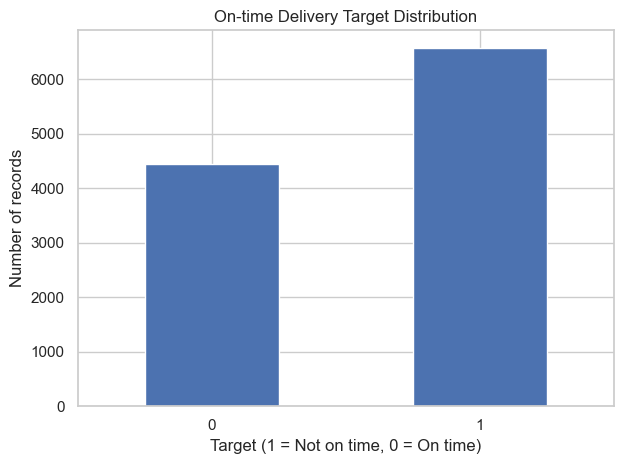

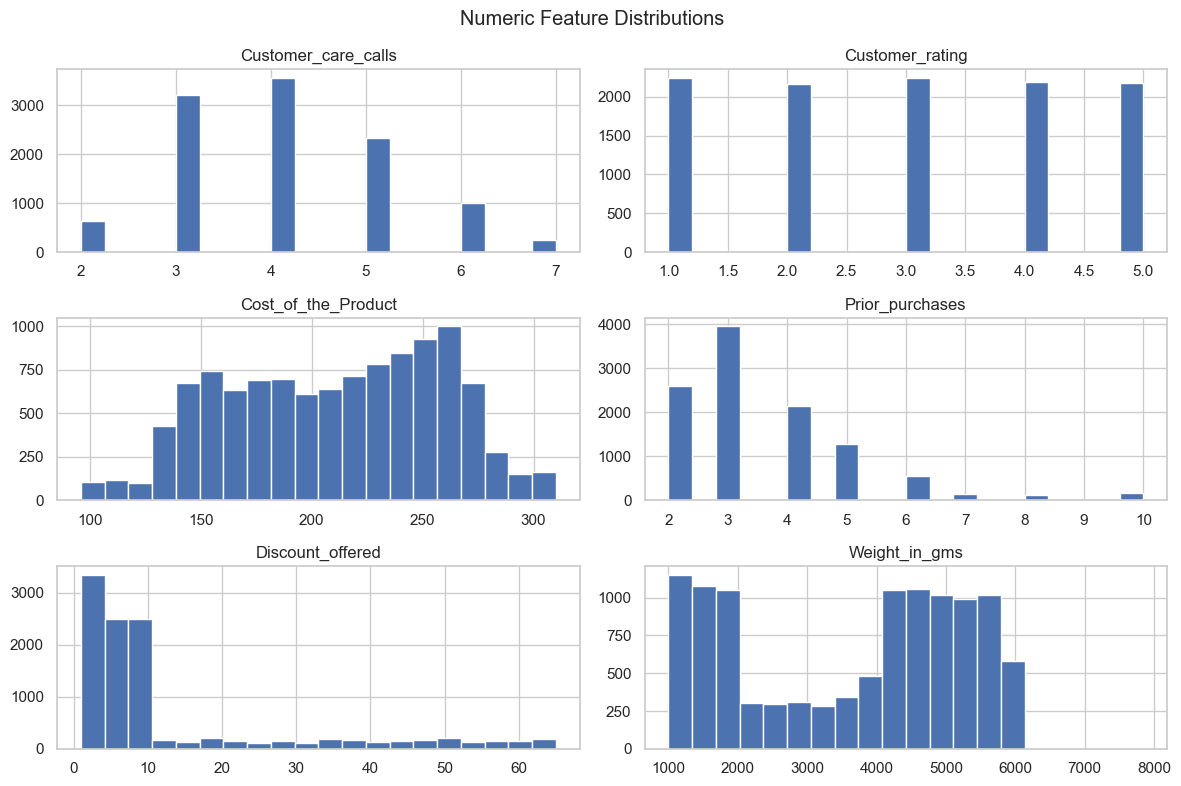

In [8]:
# Target distribution
if target in df_clean.columns:
    df_clean[target].value_counts().sort_index().plot(kind="bar")
    plt.title("On-time Delivery Target Distribution")
    plt.xlabel("Target (1 = Not on time, 0 = On time)")
    plt.ylabel("Number of records")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# Numeric feature distributions
numeric_cols = [
    c for c in ["Customer_care_calls", "Customer_rating", "Cost_of_the_Product",
                "Prior_purchases", "Discount_offered", "Weight_in_gms"]
    if c in df_clean.columns
]
if numeric_cols:
    df_clean[numeric_cols].hist(figsize=(12, 8), bins=20)
    plt.suptitle("Numeric Feature Distributions")
    plt.tight_layout()
    plt.show()


## 9. Compare delivery outcome by shipment mode

,On time (%),Not on time (%)
Mode_of_Shipment,,
Flight,39.84,60.16
Road,41.19,58.81
Ship,40.24,59.76


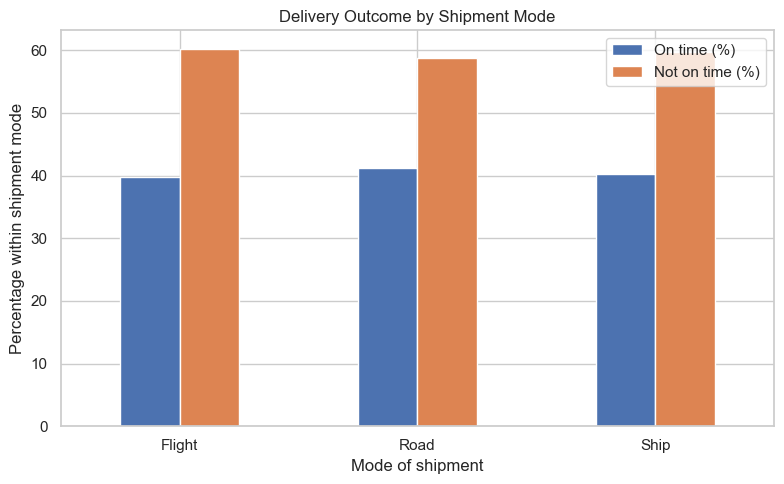

In [9]:
if "Mode_of_Shipment" in df_clean.columns and target in df_clean.columns:
    outcome_by_mode = pd.crosstab(
        df_clean["Mode_of_Shipment"],
        df_clean[target],
        normalize="index"
    ).mul(100).round(2)
    outcome_by_mode.columns = ["On time (%)" if c == 0 else "Not on time (%)"
                               for c in outcome_by_mode.columns]
    display(outcome_by_mode)
    outcome_by_mode.plot(kind="bar", figsize=(8, 5))
    plt.title("Delivery Outcome by Shipment Mode")
    plt.xlabel("Mode of shipment")
    plt.ylabel("Percentage within shipment mode")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


## 10. Correlation analysis

,ID,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
ID,1.00,0.19,-0.01,0.20,0.15,-0.60,0.28,-0.41
Customer_care_calls,0.19,1.00,0.01,0.32,0.18,-0.13,-0.28,-0.07
Customer_rating,-0.01,0.01,1.00,0.01,0.01,-0.00,-0.00,0.01
Cost_of_the_Product,0.20,0.32,0.01,1.00,0.12,-0.14,-0.13,-0.07
Prior_purchases,0.15,0.18,0.01,0.12,1.00,-0.08,-0.17,-0.06
Discount_offered,-0.60,-0.13,-0.00,-0.14,-0.08,1.00,-0.38,0.40
Weight_in_gms,0.28,-0.28,-0.00,-0.13,-0.17,-0.38,1.00,-0.27
Reached.on.Time_Y.N,-0.41,-0.07,0.01,-0.07,-0.06,0.40,-0.27,1.00


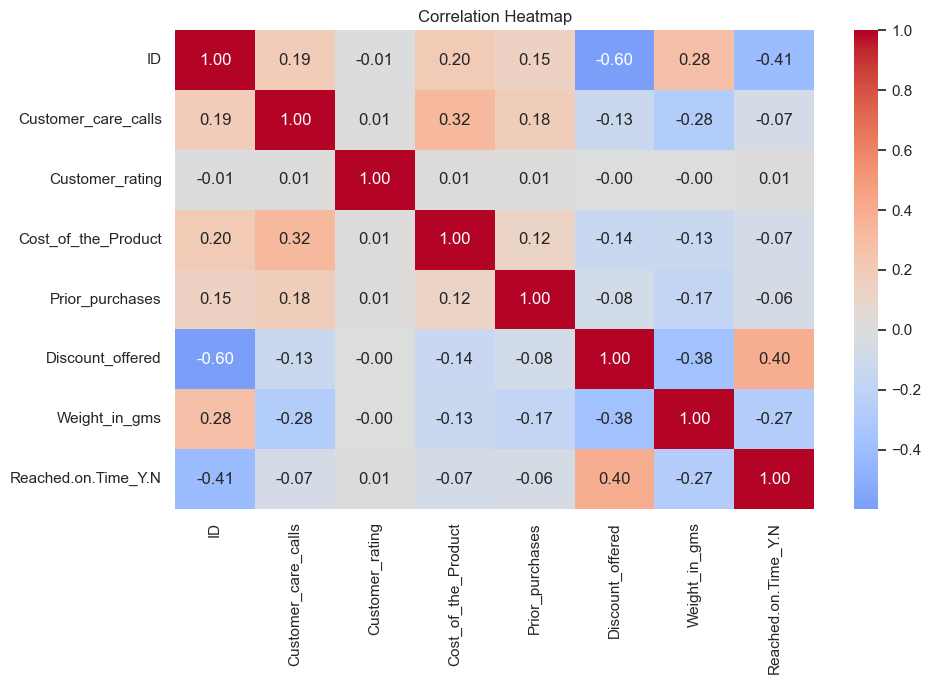

In [10]:
numeric_df = df_clean.select_dtypes(include=np.number)
if not numeric_df.empty:
    corr = numeric_df.corr(numeric_only=True)
    display(corr.round(2))
    if sns is not None:
        plt.figure(figsize=(10, 7))
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
        plt.title("Correlation Heatmap")
        plt.tight_layout()
        plt.show()


## 11. Optional: baseline machine-learning model
This section predicts the target using a train/test split and a preprocessing pipeline. It reports metrics on the test set; it does not guarantee future delivery performance.

In [11]:
# If scikit-learn is missing, run: %pip install scikit-learn
try:
    from sklearn.model_selection import train_test_split
    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from sklearn.impute import SimpleImputer
    from sklearn.pipeline import Pipeline
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

    if target not in df_clean.columns:
        raise KeyError(f"Target column '{target}' is missing.")

    model_df = df_clean.dropna(subset=[target]).copy()
    X = model_df.drop(columns=[target])
    y = model_df[target].astype(int)

    # ID is an identifier rather than a meaningful predictive feature.
    if "ID" in X.columns:
        X = X.drop(columns=["ID"])

    categorical_features = X.select_dtypes(include=["object", "string"]).columns.tolist()
    numerical_features = X.select_dtypes(include=np.number).columns.tolist()

    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer(transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ])

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
    print("\\nClassification report:")
    print(classification_report(y_test, predictions, zero_division=0))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, predictions))
except ImportError as e:
    print("Machine-learning libraries are missing. Install them with:")
    print("%pip install scikit-learn")
    print("Details:", e)


Accuracy: 0.6373
\nClassification report:
              precision    recall  f1-score   support

           0       0.55      0.59      0.57       887
           1       0.71      0.67      0.69      1313

    accuracy                           0.64      2200
   macro avg       0.63      0.63      0.63      2200
weighted avg       0.64      0.64      0.64      2200

Confusion matrix:
[[521 366]
 [432 881]]


Data Collection,Exploration and cleaning 

1. Install and import libraries

In [13]:

# Cell 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Libraries imported successfully!")


Libraries imported successfully!


2. Data Collection

In [14]:

# Cell 2: Load the dataset

file_path = Path("E_Commerce (1).csv")

if not file_path.exists():
    raise FileNotFoundError(
        "CSV file not found. Keep E_Commerce (1).csv "
        "in the same folder as your notebook."
    )

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()


Dataset loaded successfully!
Number of rows: 10999
Number of columns: 12


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


In [15]:

# Cell 3: Display the complete column names

print("Column names in the dataset:")

for column in df.columns:
    print(column)


Column names in the dataset:
ID
Warehouse_block
Mode_of_Shipment
Customer_care_calls
Customer_rating
Cost_of_the_Product
Prior_purchases
Product_importance
Gender
Discount_offered
Weight_in_gms
Reached.on.Time_Y.N


In [16]:

# Cell 4: Create a working copy

data = df.copy()

print("Working copy created.")
print("Dataset shape:", data.shape)


Working copy created.
Dataset shape: (10999, 12)


3. Data Exploration

Explore the dataset before changing any values.

In [17]:

# Cell 5: View first and last five rows

display(data.head())
display(data.tail())


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
10994,10995,A,Ship,4,1,252,5,medium,F,1,1538,1
10995,10996,B,Ship,4,1,232,5,medium,F,6,1247,0
10996,10997,C,Ship,5,4,242,5,low,F,4,1155,0
10997,10998,F,Ship,5,2,223,6,medium,M,2,1210,0
10998,10999,D,Ship,2,5,155,5,low,F,6,1639,0


In [18]:

# Cell 6: Check dataset information

data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   10999 non-null  int64 
 1   Warehouse_block      10999 non-null  object
 2   Mode_of_Shipment     10999 non-null  object
 3   Customer_care_calls  10999 non-null  int64 
 4   Customer_rating      10999 non-null  int64 
 5   Cost_of_the_Product  10999 non-null  int64 
 6   Prior_purchases      10999 non-null  int64 
 7   Product_importance   10999 non-null  object
 8   Gender               10999 non-null  object
 9   Discount_offered     10999 non-null  int64 
 10  Weight_in_gms        10999 non-null  int64 
 11  Reached.on.Time_Y.N  10999 non-null  int64 
dtypes: int64(8), object(4)
memory usage: 1.0+ MB


In [19]:

# Cell 7: Statistical summary

display(data.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,10999.0,NaN,NaN,NaN,5500.0,3175.28214,1.0,2750.5,5500.0,8249.5,10999.0
Warehouse_block,10999,5,F,3666,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mode_of_Shipment,10999,3,Ship,7462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_care_calls,10999.0,NaN,NaN,NaN,4.054459,1.14149,2.0,3.0,4.0,5.0,7.0
Customer_rating,10999.0,NaN,NaN,NaN,2.990545,1.413603,1.0,2.0,3.0,4.0,5.0
Cost_of_the_Product,10999.0,NaN,NaN,NaN,210.196836,48.063272,96.0,169.0,214.0,251.0,310.0
Prior_purchases,10999.0,NaN,NaN,NaN,3.567597,1.52286,2.0,3.0,3.0,4.0,10.0
Product_importance,10999,3,low,5297,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10999,2,F,5545,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Discount_offered,10999.0,NaN,NaN,NaN,13.373216,16.205527,1.0,4.0,7.0,10.0,65.0


In [20]:

# Cell 8: Check missing values

missing_summary = pd.DataFrame({
    "Missing_Count": data.isnull().sum(),
    "Missing_Percentage": (
        data.isnull().sum() / len(data) * 100
    ).round(2)
})

display(missing_summary.sort_values(
    "Missing_Count", ascending=False
))


,Missing_Count,Missing_Percentage
ID,0,0.0
Warehouse_block,0,0.0
Mode_of_Shipment,0,0.0
Customer_care_calls,0,0.0
Customer_rating,0,0.0
Cost_of_the_Product,0,0.0
Prior_purchases,0,0.0
Product_importance,0,0.0
Gender,0,0.0
Discount_offered,0,0.0


In [21]:

# Cell 9: Check duplicate rows

print("Total duplicate rows:", data.duplicated().sum())

# Display duplicate rows, if any
display(data[data.duplicated(keep=False)].head(10))


Total duplicate rows: 0


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N


In [22]:

# Cell 10: Check data types and unique values

for column in data.columns:
    print(f"\nColumn: {column}")
    print("Data type:", data[column].dtype)
    print("Unique values:", data[column].nunique())
    print(data[column].value_counts(dropna=False).head(10))



Column: ID
Data type: int64
Unique values: 10999
ID
1       1
7337    1
7329    1
7330    1
7331    1
7332    1
7333    1
7334    1
7335    1
7336    1
Name: count, dtype: int64

Column: Warehouse_block
Data type: object
Unique values: 5
Warehouse_block
F    3666
D    1834
A    1833
B    1833
C    1833
Name: count, dtype: int64

Column: Mode_of_Shipment
Data type: object
Unique values: 3
Mode_of_Shipment
Ship      7462
Flight    1777
Road      1760
Name: count, dtype: int64

Column: Customer_care_calls
Data type: int64
Unique values: 6
Customer_care_calls
4    3557
3    3217
5    2328
6    1013
2     638
7     246
Name: count, dtype: int64

Column: Customer_rating
Data type: int64
Unique values: 5
Customer_rating
3    2239
1    2235
4    2189
5    2171
2    2165
Name: count, dtype: int64

Column: Cost_of_the_Product
Data type: int64
Unique values: 215
Cost_of_the_Product
245    110
257    109
260    106
254    101
264    100
243    100
255     98
263     97
258     96
266     93
Name:

Reached.on.Time_Y.N
1    6563
0    4436
Name: count, dtype: int64


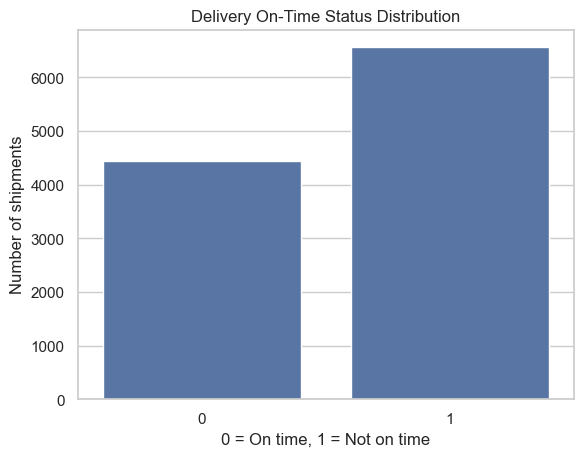

In [23]:

# Cell 11: Explore the delivery target

target = "Reached.on.Time_Y.N"

if target in data.columns:
    print(data[target].value_counts(dropna=False))

    sns.countplot(data=data, x=target)
    plt.title("Delivery On-Time Status Distribution")
    plt.xlabel("0 = On time, 1 = Not on time")
    plt.ylabel("Number of shipments")
    plt.show()
else:
    print(f"Target column '{target}' not found.")


Mode_of_Shipment
Ship      7462
Flight    1777
Road      1760
Name: count, dtype: int64

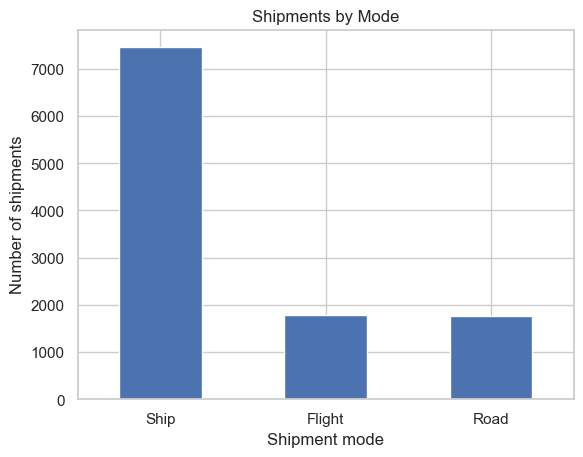

In [24]:

# Cell 12: Explore shipment methods

if "Mode_of_Shipment" in data.columns:
    display(data["Mode_of_Shipment"].value_counts())

    data["Mode_of_Shipment"].value_counts().plot(
        kind="bar", title="Shipments by Mode"
    )
    plt.xlabel("Shipment mode")
    plt.ylabel("Number of shipments")
    plt.xticks(rotation=0)
    plt.show()


4. Data Cleaning

In [25]:

# Cell 13: Standardize column names

data.columns = (
    data.columns
    .str.strip()
)

print(data.columns.tolist())


['ID', 'Warehouse_block', 'Mode_of_Shipment', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Gender', 'Discount_offered', 'Weight_in_gms', 'Reached.on.Time_Y.N']


In [26]:

# Cell 14: Remove exact duplicate rows

duplicates_before = data.duplicated().sum()

data = data.drop_duplicates().copy()

print("Duplicates before cleaning:", duplicates_before)
print("Duplicates remaining:", data.duplicated().sum())
print("Updated dataset shape:", data.shape)


Duplicates before cleaning: 0
Duplicates remaining: 0
Updated dataset shape: (10999, 12)


In [27]:

# Cell 15: Clean text columns

text_columns = data.select_dtypes(
    include=["object", "string"]
).columns

for column in text_columns:
    data[column] = data[column].str.strip()

print("Text columns cleaned.")


Text columns cleaned.


In [28]:

# Cell 16: Convert numeric columns to numeric data types

numeric_columns = [
    "ID",
    "Customer_care_calls",
    "Customer_rating",
    "Cost_of_the_Product",
    "Prior_purchases",
    "Discount_offered",
    "Weight_in_gms",
    "Reached.on.Time_Y.N"
]

for column in numeric_columns:
    if column in data.columns:
        data[column] = pd.to_numeric(
            data[column], errors="coerce"
        )

print(data.dtypes)


ID                      int64
Warehouse_block        object
Mode_of_Shipment       object
Customer_care_calls     int64
Customer_rating         int64
Cost_of_the_Product     int64
Prior_purchases         int64
Product_importance     object
Gender                 object
Discount_offered        int64
Weight_in_gms           int64
Reached.on.Time_Y.N     int64
dtype: object


In [29]:

# Cell 17: Check missing values after conversion

print(data.isnull().sum())


ID                     0
Warehouse_block        0
Mode_of_Shipment       0
Customer_care_calls    0
Customer_rating        0
Cost_of_the_Product    0
Prior_purchases        0
Product_importance     0
Gender                 0
Discount_offered       0
Weight_in_gms          0
Reached.on.Time_Y.N    0
dtype: int64


In [30]:

# Cell 18: Handle missing values

# Fill missing categorical values with the mode.
categorical_columns = data.select_dtypes(
    include=["object", "string"]
).columns

for column in categorical_columns:
    if data[column].isnull().any():
        mode_values = data[column].mode(dropna=True)

        if not mode_values.empty:
            data[column] = data[column].fillna(mode_values.iloc[0])

# Fill missing numeric values with the median,
# except the target column.
numeric_cols = data.select_dtypes(
    include="number"
).columns

for column in numeric_cols:
    if column != "Reached.on.Time_Y.N":
        if data[column].isnull().any():
            median_value = data[column].median()

            if pd.notna(median_value):
                data[column] = data[column].fillna(median_value)

# Do not guess missing target labels.
print("Missing values after cleaning:")
print(data.isnull().sum())


Missing values after cleaning:
ID                     0
Warehouse_block        0
Mode_of_Shipment       0
Customer_care_calls    0
Customer_rating        0
Cost_of_the_Product    0
Prior_purchases        0
Product_importance     0
Gender                 0
Discount_offered       0
Weight_in_gms          0
Reached.on.Time_Y.N    0
dtype: int64


In [31]:

# Cell 19: Check invalid target values

target = "Reached.on.Time_Y.N"

if target in data.columns:
    print("Target value counts:")
    print(data[target].value_counts(dropna=False))

    invalid_target = ~data[target].isin([0, 1])
    print("Invalid or missing target rows:", invalid_target.sum())


Target value counts:
Reached.on.Time_Y.N
1    6563
0    4436
Name: count, dtype: int64
Invalid or missing target rows: 0


In [32]:

# Cell 20: Check numeric values for possible errors

for column in numeric_columns:
    if column in data.columns:
        print(f"\n{column}")
        print("Minimum:", data[column].min())
        print("Maximum:", data[column].max())



ID
Minimum: 1
Maximum: 10999

Customer_care_calls
Minimum: 2
Maximum: 7

Customer_rating
Minimum: 1
Maximum: 5

Cost_of_the_Product
Minimum: 96
Maximum: 310

Prior_purchases
Minimum: 2
Maximum: 10

Discount_offered
Minimum: 1
Maximum: 65

Weight_in_gms
Minimum: 1001
Maximum: 7846

Reached.on.Time_Y.N
Minimum: 0
Maximum: 1


In [33]:

# Cell 21: Check expected categorical values

expected_categories = {
    "Warehouse_block": ["A", "B", "C", "D", "E", "F"],
    "Mode_of_Shipment": ["Ship", "Flight", "Road"],
    "Product_importance": ["low", "medium", "high"],
    "Gender": ["M", "F"]
}

for column, expected in expected_categories.items():
    if column in data.columns:
        print(f"\n{column}:")
        print("Observed:", data[column].unique())
        print("Unexpected:", 
              data.loc[
                  ~data[column].isin(expected), column
              ].dropna().unique())



Warehouse_block:
Observed: ['D' 'F' 'A' 'B' 'C']
Unexpected: []

Mode_of_Shipment:
Observed: ['Flight' 'Ship' 'Road']
Unexpected: []

Product_importance:
Observed: ['low' 'medium' 'high']
Unexpected: []

Gender:
Observed: ['F' 'M']
Unexpected: []


5. Final validation and save the cleaned dataset

In [34]:

# Cell 22: Final quality report

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", data.shape)
print("Duplicate rows remaining:", data.duplicated().sum())

print("\nMissing values:")
display(data.isnull().sum().to_frame("Missing_Count"))

print("\nFinal data types:")
display(data.dtypes.to_frame("Data_Type"))


Original dataset shape: (10999, 12)
Cleaned dataset shape: (10999, 12)
Duplicate rows remaining: 0

Missing values:


,Missing_Count
ID,0
Warehouse_block,0
Mode_of_Shipment,0
Customer_care_calls,0
Customer_rating,0
Cost_of_the_Product,0
Prior_purchases,0
Product_importance,0
Gender,0
Discount_offered,0



Final data types:


,Data_Type
ID,int64
Warehouse_block,object
Mode_of_Shipment,object
Customer_care_calls,int64
Customer_rating,int64
Cost_of_the_Product,int64
Prior_purchases,int64
Product_importance,object
Gender,object
Discount_offered,int64


In [35]:

# Cell 23: Save the cleaned dataset

output_path = Path("E_Commerce_Cleaned.csv")

data.to_csv(output_path, index=False)

print("Cleaned dataset saved to:", output_path.resolve())


Cleaned dataset saved to: C:\Users\MIS\Downloads\E_Commerce_cleaned.csv


EDA (EXPLORATORY DATA ANALYSIS)

E-COMMERCE EXPLORATORY DATA ANALYSIS

1. DATASET SHAPE
Rows: 10999
Columns: 12

2. FIRST FIVE ROWS
   ID Warehouse_block Mode_of_Shipment  Customer_care_calls  Customer_rating  \
0   1               D           Flight                    4                2   
1   2               F           Flight                    4                5   
2   3               A           Flight                    2                2   
3   4               B           Flight                    3                3   
4   5               C           Flight                    2                2   

   Cost_of_the_Product  Prior_purchases Product_importance Gender  \
0                  177                3                low      F   
1                  216                2                low      M   
2                  183                4                low      M   
3                  176                4             medium      M   
4                  184                3             medium      F   

   Di

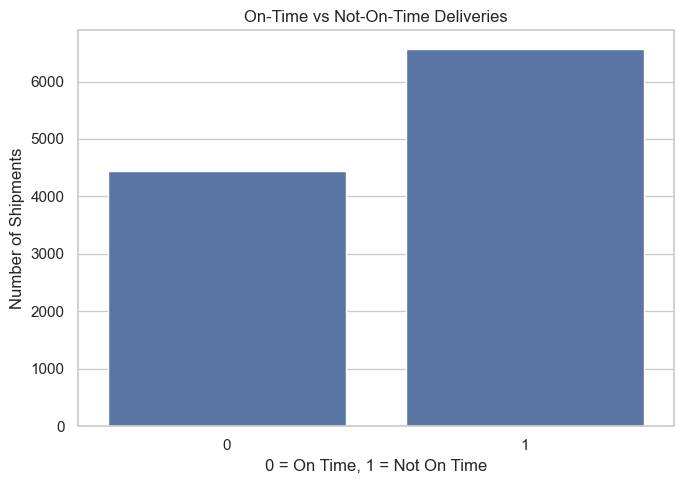

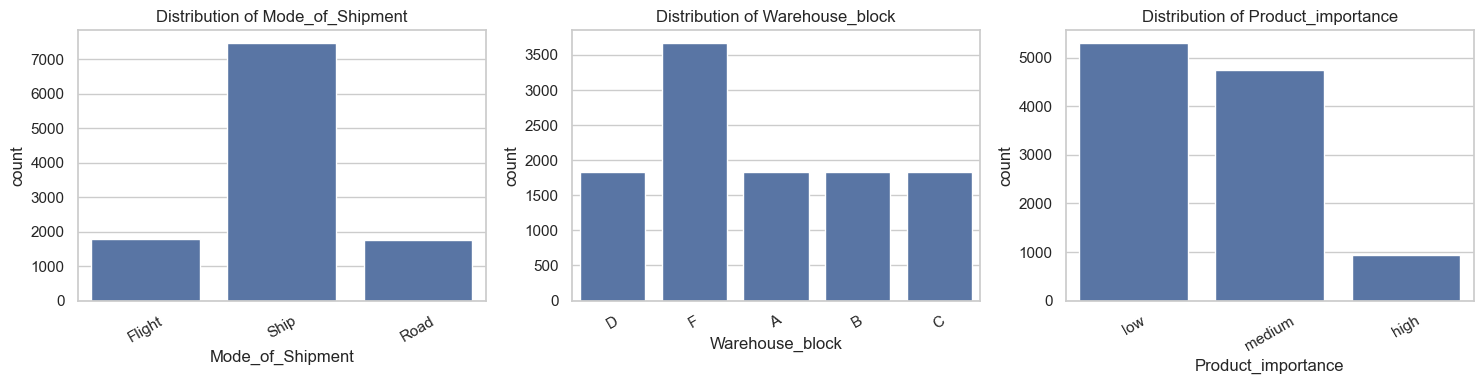

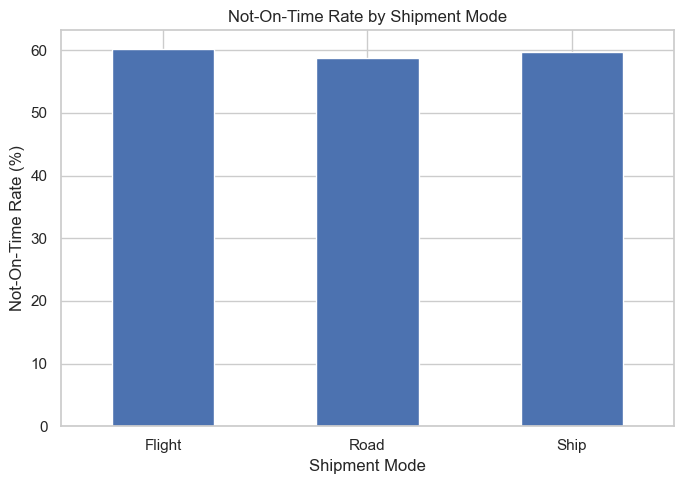

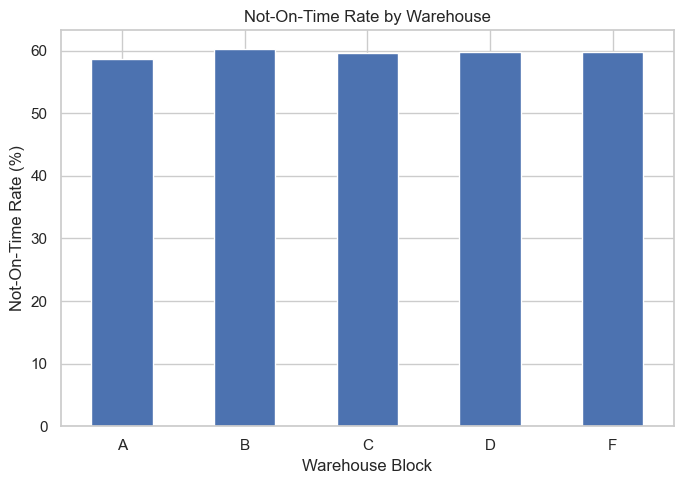

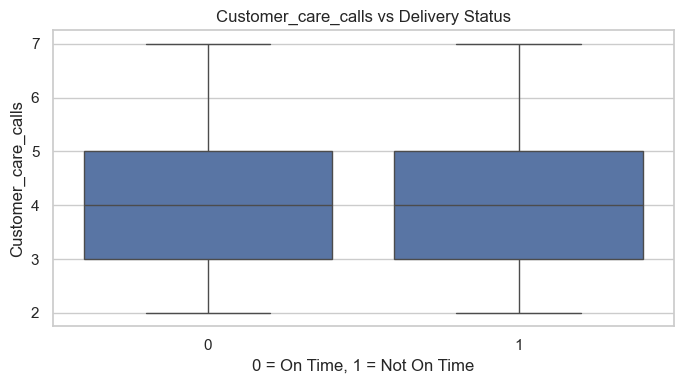

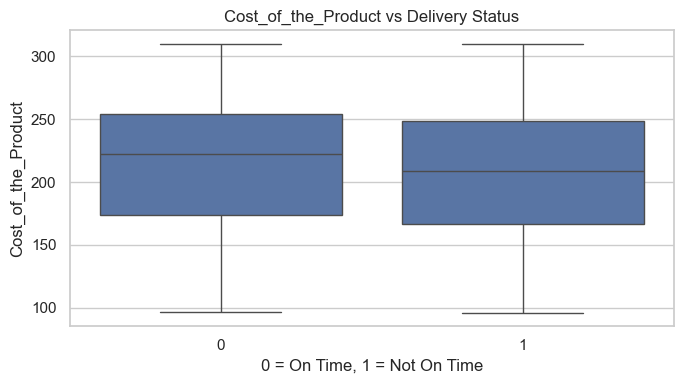

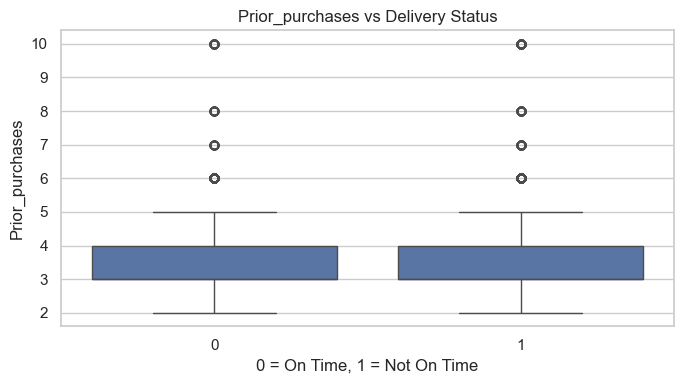

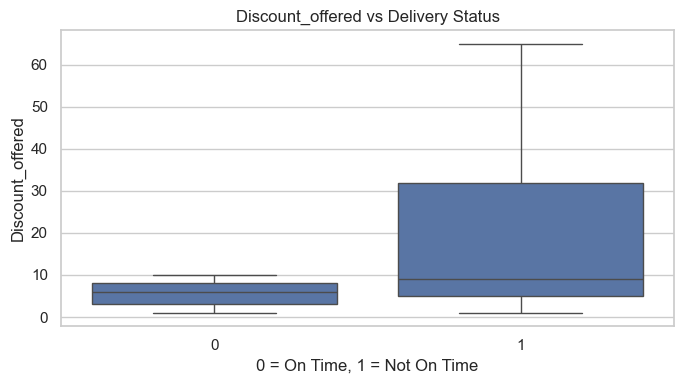

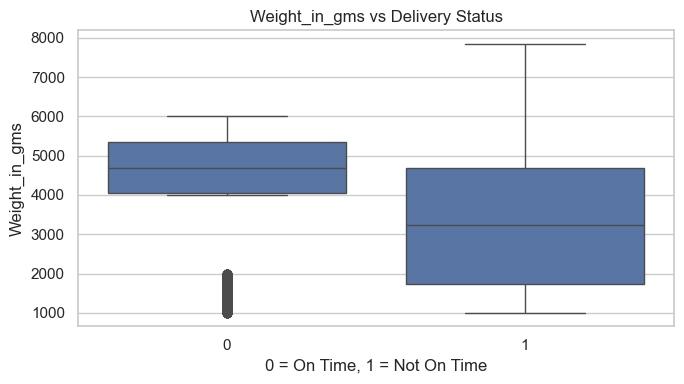

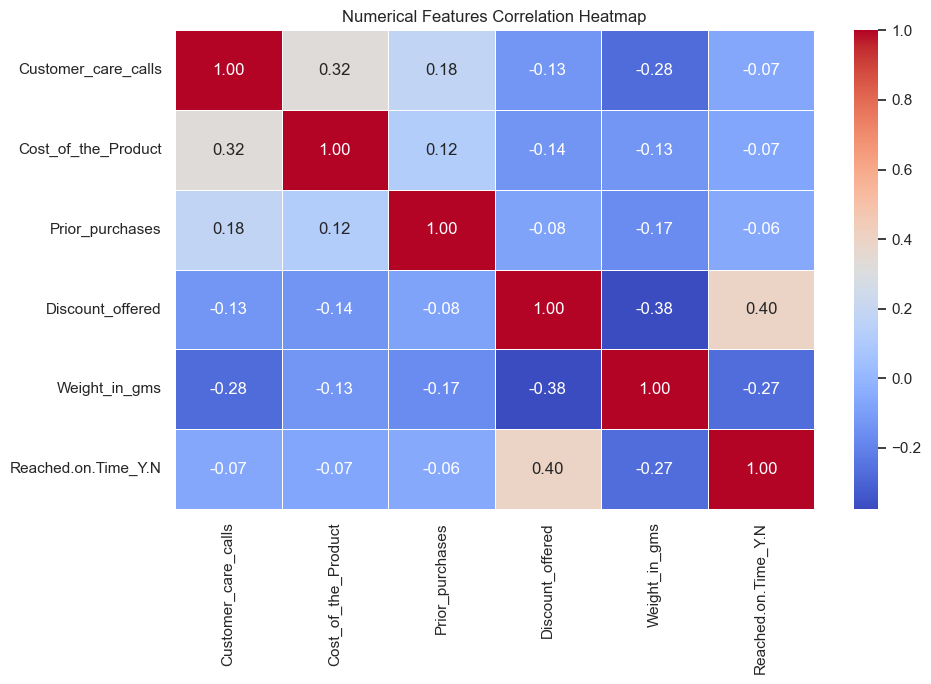


FINAL EDA SUMMARY
Total shipments: 10999
Total columns: 12
Duplicate rows: 0
Total missing cells: 0
On-time deliveries (0): 4436
Not-on-time deliveries (1): 6563
Not-on-time rate: 59.67 %
Most common shipment mode: Ship
Most common warehouse block: F

EDA completed successfully!


In [36]:

# ============================================================
# E-COMMERCE DELIVERY PERFORMANCE ANALYSIS - COMPLETE EDA
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# 1. DATA COLLECTION
file_path = Path("E_Commerce (1).csv")

if not file_path.exists():
    alternatives = [
        Path("E_Commerce.csv"),
        Path("E_Commerce_Cleaned.csv")
    ]
    file_path = next(
        (p for p in alternatives if p.exists()), None
    )

if file_path is None:
    raise FileNotFoundError(
        "Dataset not found. Keep E_Commerce (1).csv "
        "in the same folder as this notebook."
    )

df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()

print("=" * 60)
print("E-COMMERCE EXPLORATORY DATA ANALYSIS")
print("=" * 60)

# 2. BASIC DATA EXPLORATION
print("\n1. DATASET SHAPE")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n2. FIRST FIVE ROWS")
print(df.head())

print("\n3. COLUMN NAMES")
print(df.columns.tolist())

print("\n4. DATA TYPES AND NON-NULL COUNTS")
df.info()

print("\n5. STATISTICAL SUMMARY")
print(df.describe(include="all").T)

# 3. DATA QUALITY CHECKS
print("\n6. MISSING VALUES")
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})
print(missing)

print("\n7. DUPLICATE ROWS")
print("Duplicate count:", df.duplicated().sum())

print("\n8. UNIQUE VALUES")
print(df.nunique())

# 4. TARGET VARIABLE ANALYSIS
target = "Reached.on.Time_Y.N"

if target not in df.columns:
    raise ValueError(f"Target column '{target}' not found.")

print("\n9. DELIVERY STATUS COUNTS")
print(df[target].value_counts(dropna=False))

print("\n10. DELIVERY STATUS PERCENTAGES")
print(
    (df[target].value_counts(normalize=True) * 100)
    .round(2)
)

# 5. CATEGORICAL FEATURE ANALYSIS
categorical_cols = [
    "Warehouse_block",
    "Mode_of_Shipment",
    "Product_importance",
    "Gender",
    "Customer_rating"
]

for col in categorical_cols:
    if col in df.columns:
        print(f"\n11. DISTRIBUTION: {col}")
        print(df[col].value_counts(dropna=False))

# 6. DELIVERY PERFORMANCE BY CATEGORY
for col in [
    "Mode_of_Shipment",
    "Warehouse_block",
    "Product_importance",
    "Gender",
    "Customer_rating"
]:
    if col in df.columns:
        print(f"\n12. NOT-ON-TIME RATE BY {col}")
        result = (
            df.groupby(col, dropna=False)[target]
            .agg(["count", "mean"])
        )
        result["Not_On_Time_Percentage"] = (
            result["mean"] * 100
        ).round(2)
        print(result.drop(columns="mean"))

# 7. NUMERICAL FEATURE ANALYSIS
numeric_cols = [
    "Customer_care_calls",
    "Cost_of_the_Product",
    "Prior_purchases",
    "Discount_offered",
    "Weight_in_gms"
]

available_numeric = [
    col for col in numeric_cols if col in df.columns
]

print("\n13. NUMERICAL FEATURE SUMMARY")
if available_numeric:
    print(df[available_numeric].describe().T)

# 8. VISUALIZATION 1: DELIVERY STATUS
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x=target)
plt.title("On-Time vs Not-On-Time Deliveries")
plt.xlabel("0 = On Time, 1 = Not On Time")
plt.ylabel("Number of Shipments")
plt.tight_layout()
plt.show()

# 9. VISUALIZATION 2: CATEGORICAL DISTRIBUTIONS
plot_categories = [
    "Mode_of_Shipment",
    "Warehouse_block",
    "Product_importance"
]
plot_categories = [
    c for c in plot_categories if c in df.columns
]

if plot_categories:
    fig, axes = plt.subplots(
        1, len(plot_categories),
        figsize=(5 * len(plot_categories), 4)
    )
    axes = np.atleast_1d(axes)

    for ax, col in zip(axes, plot_categories):
        sns.countplot(data=df, x=col, ax=ax)
        ax.set_title(f"Distribution of {col}")
        ax.tick_params(axis="x", rotation=30)

    plt.tight_layout()
    plt.show()

# 10. VISUALIZATION 3: DELIVERY RATE BY SHIPMENT MODE
if "Mode_of_Shipment" in df.columns:
    mode_rate = (
        df.groupby("Mode_of_Shipment")[target]
        .mean() * 100
    )

    plt.figure(figsize=(7, 5))
    mode_rate.plot(kind="bar")
    plt.title("Not-On-Time Rate by Shipment Mode")
    plt.xlabel("Shipment Mode")
    plt.ylabel("Not-On-Time Rate (%)")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# 11. VISUALIZATION 4: WAREHOUSE DELIVERY RATE
if "Warehouse_block" in df.columns:
    warehouse_rate = (
        df.groupby("Warehouse_block")[target]
        .mean() * 100
    )

    plt.figure(figsize=(7, 5))
    warehouse_rate.plot(kind="bar")
    plt.title("Not-On-Time Rate by Warehouse")
    plt.xlabel("Warehouse Block")
    plt.ylabel("Not-On-Time Rate (%)")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# 12. VISUALIZATION 5: NUMERICAL FEATURES VS TARGET
for col in available_numeric:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x=target, y=col)
    plt.title(f"{col} vs Delivery Status")
    plt.xlabel("0 = On Time, 1 = Not On Time")
    plt.tight_layout()
    plt.show()

# 13. VISUALIZATION 6: CORRELATION HEATMAP
corr_cols = available_numeric.copy()

if target in df.columns and pd.api.types.is_numeric_dtype(df[target]):
    corr_cols.append(target)

if len(corr_cols) >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        df[corr_cols].corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5
    )
    plt.title("Numerical Features Correlation Heatmap")
    plt.tight_layout()
    plt.show()

# 14. FINAL BUSINESS SUMMARY
print("\n" + "=" * 60)
print("FINAL EDA SUMMARY")
print("=" * 60)

print("Total shipments:", len(df))
print("Total columns:", df.shape[1])
print("Duplicate rows:", df.duplicated().sum())
print("Total missing cells:", int(df.isnull().sum().sum()))

valid_target = df[target].dropna()

if len(valid_target) > 0:
    print(
        "On-time deliveries (0):",
        int((valid_target == 0).sum())
    )
    print(
        "Not-on-time deliveries (1):",
        int((valid_target == 1).sum())
    )
    print(
        "Not-on-time rate:",
        round((valid_target == 1).mean() * 100, 2),
        "%"
    )

if "Mode_of_Shipment" in df.columns:
    print(
        "Most common shipment mode:",
        df["Mode_of_Shipment"].mode().iloc[0]
    )

if "Warehouse_block" in df.columns:
    print(
        "Most common warehouse block:",
        df["Warehouse_block"].mode().iloc[0]
    )

print("\nEDA completed successfully!")
print("=" * 60)


Data Preprocessing and Feature Engineering 

In [37]:

# ============================================================
# E-COMMERCE PROJECT
# DATA PREPROCESSING AND FEATURE ENGINEERING
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler

# 1. LOAD DATASET
file_path = Path("E_Commerce (1).csv")

if not file_path.exists():
    alternatives = [
        Path("E_Commerce.csv"),
        Path("E_Commerce_Cleaned.csv")
    ]
    file_path = next(
        (p for p in alternatives if p.exists()), None
    )

if file_path is None:
    raise FileNotFoundError(
        "Dataset not found. Keep the CSV file in the notebook folder."
    )

df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()

print("Dataset loaded successfully:", df.shape)

# 2. CREATE A WORKING COPY
data = df.copy()

# 3. REMOVE EXACT DUPLICATE ROWS
data.drop_duplicates(inplace=True)
data.reset_index(drop=True, inplace=True)

print("Duplicates removed. Shape:", data.shape)

# 4. CLEAN TEXT COLUMNS
text_cols = data.select_dtypes(
    include=["object", "string"]
).columns

for col in text_cols:
    data[col] = data[col].str.strip()

# 5. CONVERT NUMERIC COLUMNS
numeric_cols = [
    "ID",
    "Customer_care_calls",
    "Customer_rating",
    "Cost_of_the_Product",
    "Prior_purchases",
    "Discount_offered",
    "Weight_in_gms",
    "Reached.on.Time_Y.N"
]

for col in numeric_cols:
    if col in data.columns:
        data[col] = pd.to_numeric(
            data[col], errors="coerce"
        )

# 6. HANDLE MISSING VALUES
target = "Reached.on.Time_Y.N"

# Fill missing feature values with median or mode
for col in data.columns:
    if col == target:
        continue

    if pd.api.types.is_numeric_dtype(data[col]):
        if data[col].isnull().any():
            median = data[col].median()
            if pd.notna(median):
                data[col] = data[col].fillna(median)
    else:
        if data[col].isnull().any():
            mode = data[col].mode(dropna=True)
            if not mode.empty:
                data[col] = data[col].fillna(mode.iloc[0])

# Remove rows with missing target labels
if target in data.columns:
    data = data.dropna(subset=[target]).copy()

    # Only 0 and 1 are valid target values
    data = data[data[target].isin([0, 1])].copy()
    data[target] = data[target].astype(int)

print("Missing values handled.")
print("Remaining missing values:", int(data.isnull().sum().sum()))

# 7. VALIDATE CATEGORICAL VALUES
category_cols = [
    "Warehouse_block",
    "Mode_of_Shipment",
    "Product_importance",
    "Gender"
]

for col in category_cols:
    if col in data.columns:
        data[col] = data[col].replace("", np.nan)

        if data[col].isnull().any():
            mode = data[col].mode(dropna=True)
            if not mode.empty:
                data[col] = data[col].fillna(mode.iloc[0])

# 8. FEATURE ENGINEERING
# Create total customer interaction indicator
if "Customer_care_calls" in data.columns:
    data["High_Care_Calls"] = (
        data["Customer_care_calls"] >= 4
    ).astype(int)

# Create product cost category
if "Cost_of_the_Product" in data.columns:
    data["Product_Cost_Category"] = pd.cut(
        data["Cost_of_the_Product"],
        bins=[-np.inf, 100, 200, np.inf],
        labels=["Low", "Medium", "High"]
    )

# Create product weight category
if "Weight_in_gms" in data.columns:
    data["Product_Weight_Category"] = pd.cut(
        data["Weight_in_gms"],
        bins=[-np.inf, 2000, 5000, np.inf],
        labels=["Light", "Medium", "Heavy"]
    )

# 9. SEPARATE FEATURES AND TARGET
if target not in data.columns:
    raise ValueError(f"Target column '{target}' not found.")

X = data.drop(columns=[target]).copy()
y = data[target].copy()

# Remove ID because it is an identifier, not a useful
# general predictive feature
if "ID" in X.columns:
    X = X.drop(columns=["ID"])

print("Features shape:", X.shape)
print("Target shape:", y.shape)

# 10. ENCODE CATEGORICAL FEATURES
# One-hot encoding converts categories into numeric columns
X_encoded = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

print("Encoded features shape:", X_encoded.shape)

# 11. SCALE NUMERICAL FEATURES
# Scaling is useful for models sensitive to feature magnitude.
# Fit the scaler here for demonstration; for ML evaluation,
# fit it only on the training data to avoid data leakage.

scaler = StandardScaler()

numeric_features = X_encoded.select_dtypes(
    include=np.number
).columns.tolist()

X_scaled = X_encoded.copy()

if numeric_features:
    X_scaled[numeric_features] = scaler.fit_transform(
        X_encoded[numeric_features]
    )

print("Feature scaling completed.")

# 12. FINAL CHECK
print("\nFINAL DATA PREPROCESSING SUMMARY")
print("--------------------------------")
print("Rows:", len(X_scaled))
print("Number of features:", X_scaled.shape[1])
print("Missing values:", int(X_scaled.isnull().sum().sum()))
print("Duplicate rows:", int(X_scaled.duplicated().sum()))

print("\nTarget distribution:")
print(y.value_counts())

print("\nSample processed features:")
display(X_scaled.head())

# 13. SAVE OUTPUT FILES
data.to_csv("E_Commerce_Preprocessed.csv", index=False)
X_encoded.to_csv("E_Commerce_Features_Encoded.csv", index=False)
X_scaled.to_csv("E_Commerce_Features_Scaled.csv", index=False)
y.to_csv("E_Commerce_Target.csv", index=False)

print("\nFiles saved successfully:")
print("1. E_Commerce_Preprocessed.csv")
print("2. E_Commerce_Features_Encoded.csv")
print("3. E_Commerce_Features_Scaled.csv")
print("4. E_Commerce_Target.csv")
print("\nPreprocessing and feature engineering completed!")


Dataset loaded successfully: (10999, 12)
Duplicates removed. Shape: (10999, 12)
Missing values handled.
Remaining missing values: 0
Features shape: (10999, 13)
Target shape: (10999,)
Encoded features shape: (10999, 20)
Feature scaling completed.

FINAL DATA PREPROCESSING SUMMARY
--------------------------------
Rows: 10999
Number of features: 20
Missing values: 0
Duplicate rows: 0

Target distribution:
Reached.on.Time_Y.N
1    6563
0    4436
Name: count, dtype: int64

Sample processed features:


,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,High_Care_Calls,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F,Mode_of_Shipment_Road,Mode_of_Shipment_Ship,Product_importance_low,Product_importance_medium,Gender_M,Product_Cost_Category_Medium,Product_Cost_Category_High,Product_Weight_Category_Medium,Product_Weight_Category_Heavy
0,-0.047711,-0.700755,-0.690722,-0.372735,1.889983,-1.468240,0.734584,-0.447189,-0.447189,2.235458,-0.707059,-0.436459,-1.45248,1.037525,-0.872496,-0.991760,1.174828,-1.166102,-0.890573,-0.596847
1,-0.047711,1.421578,0.120746,-1.029424,2.815636,-0.333893,0.734584,-0.447189,-0.447189,-0.447336,1.414310,-0.436459,-1.45248,1.037525,-0.872496,1.008308,-0.851188,0.857558,1.122873,-0.596847
2,-1.799887,-0.700755,-0.565881,0.283954,2.136824,-0.159002,-1.361315,-0.447189,-0.447189,-0.447336,-0.707059,-0.436459,-1.45248,1.037525,-0.872496,1.008308,1.174828,-1.166102,1.122873,-0.596847
3,-0.923799,0.006689,-0.711529,0.283954,-0.208162,-1.502484,-1.361315,2.236190,-0.447189,-0.447336,-0.707059,-0.436459,-1.45248,-0.963832,1.146137,1.008308,1.174828,-1.166102,-0.890573,-0.596847
4,-1.799887,-0.700755,-0.545074,-0.372735,2.013404,-0.703244,-1.361315,-0.447189,2.236190,-0.447336,-0.707059,-0.436459,-1.45248,-0.963832,1.146137,-0.991760,1.174828,-1.166102,1.122873,-0.596847



Files saved successfully:
1. E_Commerce_Preprocessed.csv
2. E_Commerce_Features_Encoded.csv
3. E_Commerce_Features_Scaled.csv
4. E_Commerce_Target.csv

Preprocessing and feature engineering completed!


Data Modeling, Model Selection and Training

In [2]:
# ============================================================
# E-COMMERCE DELIVERY PERFORMANCE ANALYSIS
# MODEL SELECTION AND TRAINING
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [2]:
# ------------------------------------------------------------
# 1. LOAD DATASET
# ------------------------------------------------------------

file_path = Path("E_Commerce (1).csv")

if not file_path.exists():
    alternatives = [
        Path("E_Commerce.csv"),
        Path("E_Commerce_Cleaned.csv"),
        Path("E_Commerce_Preprocessed.csv")
    ]

    file_path = next(
        (p for p in alternatives if p.exists()), None
    )

if file_path is None:
    raise FileNotFoundError(
        "Dataset not found. Place your E-Commerce CSV "
        "file in the same folder as this notebook."
    )

df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Original dataset shape:", df.shape)


Dataset loaded successfully!
Original dataset shape: (10999, 12)


In [3]:
# ------------------------------------------------------------
# 2. DATA PREPARATION
# ------------------------------------------------------------

target = "Reached.on.Time_Y.N"

if target not in df.columns:
    raise ValueError(f"Target column '{target}' not found.")

df = df.drop_duplicates().copy()

df[target] = pd.to_numeric(df[target], errors="coerce")
df = df.dropna(subset=[target]).copy()

# Keep only valid binary target labels
df = df[df[target].isin([0, 1])].copy()
df[target] = df[target].astype(int)

# Separate features and target
X = df.drop(columns=[target]).copy()
y = df[target].copy()

# ID is an identifier and is excluded from predictors
if "ID" in X.columns:
    X = X.drop(columns=["ID"])

# Replace infinite values with missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Identify numerical and categorical features
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("\nNumerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("\nTarget distribution:")
print(y.value_counts())



Numerical features: ['Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms']
Categorical features: ['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']

Target distribution:
Reached.on.Time_Y.N
1    6563
0    4436
Name: count, dtype: int64


In [16]:
# ------------------------------------------------------------
# 3. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ------------------------------------------------------------

numerical_features = X.select_dtypes(
    include=["int64", "int32", "float64", "float32"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumerical features:", numerical_features)
print("\nCategorical features:", categorical_features)



Numerical features: ['Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms']

Categorical features: ['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']


In [ ]:
# ------------------------------------------------------------
# 4. SPLIT DATA INTO TRAINING AND TESTING
# ------------------------------------------------------------

stratify_target = y if y.value_counts().min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=stratify_target
)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (8799, 10)
Testing data: (2200, 10)


In [21]:
# ------------------------------------------------------------
# 5. DATA PREPROCESSING PIPELINE
# ------------------------------------------------------------

import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Define numerical and categorical features
numerical_features = [
    "Customer_care_calls",
    "Customer_rating",
    "Cost_of_the_Product",
    "Prior_purchases",
    "Discount_offered",
    "Weight_in_gms"
]

categorical_features = [
    "Warehouse_block",
    "Mode_of_Shipment",
    "Product_importance",
    "Gender"
]

# Numerical preprocessing pipeline
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing pipeline
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Data Preprocessing Pipeline Created Successfully!")
print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Data Preprocessing Pipeline Created Successfully!
Numerical Features: ['Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms']
Categorical Features: ['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']


In [2]:
# ------------------------------------------------------------
# 6. DEFINE CROSS-VALIDATION
# ------------------------------------------------------------

from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

print("Cross-validation defined successfully!")
print("Number of folds:", cv.n_splits)
print("Shuffle:", cv.shuffle)
print("Random state:", cv.random_state)

Cross-validation defined successfully!
Number of folds: 3
Shuffle: True
Random state: 42


In [19]:

# ------------------------------------------------------------
# 10. DEFINE MODELS FOR E-COMMERCE PRODUCT DELIVERY PREDICTION
# ------------------------------------------------------------

import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

from sklearn.neural_network import MLPClassifier

# ------------------------------------------------------------
# 1. Logistic Regression
# ------------------------------------------------------------

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# ------------------------------------------------------------
# 2. Decision Tree
# ------------------------------------------------------------

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

# ------------------------------------------------------------
# 3. Optimized Random Forest
# ------------------------------------------------------------

random_forest_model = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid={
        "n_estimators": [100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2]
    },
    cv=3,
    scoring="f1",
    n_jobs=-1
)

# ------------------------------------------------------------
# 4. Optimized Gradient Boosting
# ------------------------------------------------------------

gradient_boosting_model = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_grid={
        "n_estimators": [100, 200],
        "learning_rate": [0.05, 0.1],
        "max_depth": [2, 3],
        "min_samples_split": [2, 5]
    },
    cv=3,
    scoring="f1",
    n_jobs=-1
)

# ------------------------------------------------------------
# 5. K-Nearest Neighbors (KNN)
# ------------------------------------------------------------

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

# ------------------------------------------------------------
# 6. Support Vector Machine (SVM)
# ------------------------------------------------------------

svm_model = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

# ------------------------------------------------------------
# 7. Default Neural Network
# ------------------------------------------------------------

default_nn_model = MLPClassifier(
    hidden_layer_sizes=(100,),
    activation="relu",
    solver="adam",
    max_iter=300,
    random_state=42
)

# ------------------------------------------------------------
# 8. Fine-Tuned Neural Network
# ------------------------------------------------------------

fine_tuned_nn_model = GridSearchCV(
    estimator=MLPClassifier(
        max_iter=300,
        random_state=42,
        early_stopping=True
    ),
    param_grid={
        "hidden_layer_sizes": [(64,), (100,), (100, 50)],
        "activation": ["relu", "tanh"],
        "alpha": [0.0001, 0.001],
        "learning_rate_init": [0.001, 0.01]
    },
    cv=3,
    scoring="f1",
    n_jobs=-1
)

# ------------------------------------------------------------
# 9. Store All Models in One Dictionary
# ------------------------------------------------------------

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Optimized Random Forest": random_forest_model,
    "Optimized Gradient Boosting": gradient_boosting_model,
    "K-Nearest Neighbors": knn_model,
    "Support Vector Machine": svm_model,
    "Default Neural Network": default_nn_model,
    "Fine-Tuned Neural Network": fine_tuned_nn_model
}

# ------------------------------------------------------------
# 10. Display Defined Models
# ------------------------------------------------------------

print("E-commerce Product Delivery Prediction")
print("Models Defined Successfully!\n")

for model_name, model in models.items():
    print(f"{model_name}: {model.__class__.__name__}")


E-commerce Product Delivery Prediction
Models Defined Successfully!

Logistic Regression: LogisticRegression
Decision Tree: DecisionTreeClassifier
Optimized Random Forest: GridSearchCV
Optimized Gradient Boosting: GridSearchCV
K-Nearest Neighbors: KNeighborsClassifier
Support Vector Machine: SVC
Default Neural Network: MLPClassifier
Fine-Tuned Neural Network: GridSearchCV


In [3]:
# ------------------------------------------------------------
# 7. HYPERPARAMETER SEARCH SPACES
# ------------------------------------------------------------

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

param_spaces = {
    "Random Forest (Optimized)": {
        "model__n_estimators": [100, 150, 200],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_split": [2, 5],
        "model__min_samples_leaf": [1, 2],
        "model__max_features": ["sqrt", 0.8]
    },

    "Gradient Boosting (Optimized)": {
        "model__n_estimators": [100, 150, 200],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [2, 3],
        "model__subsample": [0.8, 1.0]
    }
}

print("Hyperparameter search spaces defined successfully!")

for model_name, params in param_spaces.items():
    print(f"\n{model_name}")
    for parameter, values in params.items():
        print(f"{parameter}: {values}")

Hyperparameter search spaces defined successfully!

Random Forest (Optimized)
model__n_estimators: [100, 150, 200]
model__max_depth: [None, 10, 20]
model__min_samples_split: [2, 5]
model__min_samples_leaf: [1, 2]
model__max_features: ['sqrt', 0.8]

Gradient Boosting (Optimized)
model__n_estimators: [100, 150, 200]
model__learning_rate: [0.03, 0.05, 0.1]
model__max_depth: [2, 3]
model__subsample: [0.8, 1.0]


In [12]:
# ------------------------------------------------------------
# 8. DEFINE TRAINING DATA AND PREPROCESSOR
# ------------------------------------------------------------

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# 1. Load the dataset
# Change the filename if your dataset has a different name
df = pd.read_csv("E_Commerce (1).csv")

# 2. Remove unnecessary ID column if present
if "ID" in df.columns:
    df = df.drop(columns=["ID"])

# 3. Define the target column
target_column = "Reached.on.Time_Y.N"

if target_column not in df.columns:
    raise ValueError(
        f"Target column '{target_column}' not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# 4. Separate features and target
X = df.drop(columns=[target_column])
y = df[target_column]

# 5. Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 6. Identify numerical and categorical features
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# 7. Create numerical preprocessing pipeline
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 8. Create categorical preprocessing pipeline
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# 9. Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Training data and preprocessor defined successfully!")
print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)
print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

Training data and preprocessor defined successfully!
Training Shape: (8799, 10)
Testing Shape: (2200, 10)
Numerical Features: ['Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms']
Categorical Features: ['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']


In [13]:
# ------------------------------------------------------------
# 9. FIT PREPROCESSING ON TRAINING DATA ONLY
# ------------------------------------------------------------

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\nData Preprocessing Completed Successfully!")
print("Original Training Shape:", X_train.shape)
print("Processed Training Shape:", X_train_processed.shape)
print("Original Testing Shape:", X_test.shape)
print("Processed Testing Shape:", X_test_processed.shape)


Data Preprocessing Completed Successfully!
Original Training Shape: (8799, 10)
Processed Training Shape: (8799, 19)
Original Testing Shape: (2200, 10)
Processed Testing Shape: (2200, 19)


In [11]:
# ------------------------------------------------------------
# 9. FINE-TUNED NEURAL NETWORK
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("Fine-Tuning Neural Network")
print("=" * 60)

nn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", MLPClassifier(
        max_iter=300,
        early_stopping=True,
        random_state=42
    ))
])

nn_param_space = {
    "model__hidden_layer_sizes": [
        (32,), (64, 32), (100, 50)
    ],
    "model__activation": ["relu", "tanh"],
    "model__alpha": [0.0001, 0.001],
    "model__learning_rate_init": [0.001, 0.01]
}

nn_search = RandomizedSearchCV(
    estimator=nn_pipeline,
    param_distributions=nn_param_space,
    n_iter=6,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True
)

nn_search.fit(X_train, y_train)

fine_tuned_nn = nn_search.best_estimator_
trained_models["Fine-Tuned Neural Network"] = fine_tuned_nn

nn_pred = fine_tuned_nn.predict(X_test)
nn_prob = fine_tuned_nn.predict_proba(X_test)[:, 1]

results.append({
    "Model": "Fine-Tuned Neural Network",
    "Accuracy": accuracy_score(y_test, nn_pred),
    "Precision": precision_score(
        y_test, nn_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, nn_pred, zero_division=0
    ),
    "F1_Score": f1_score(
        y_test, nn_pred, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test, nn_prob)
})

print("Best NN CV F1:", round(nn_search.best_score_, 4))
print("Best NN parameters:", nn_search.best_params_)



Fine-Tuning Neural Network
Best NN CV F1: 0.6966
Best NN parameters: {'model__learning_rate_init': 0.001, 'model__hidden_layer_sizes': (32,), 'model__alpha': 0.001, 'model__activation': 'tanh'}


In [12]:
# ------------------------------------------------------------
# 10. COMPARE ALL MODELS
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1_Score",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 60)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 60)

display(results_df.round(4))



MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Decision Tree,0.6405,0.6900,0.7220,0.7056,0.6209
1,Fine-Tuned Neural Network,0.6459,0.7051,0.6992,0.7021,0.7291
2,Random Forest (Optimized),0.6591,0.7571,0.6314,0.6885,0.7375
3,Logistic Regression,0.6373,0.7065,0.6710,0.6883,0.7173
4,Default Neural Network,0.6573,0.7576,0.6260,0.6856,0.7317
5,K-Nearest Neighbors,0.6305,0.7049,0.6550,0.6790,0.7012
6,Gradient Boosting (Optimized),0.6750,0.8738,0.5324,0.6616,0.7466
7,Support Vector Machine,0.6627,0.8371,0.5400,0.6565,0.7348


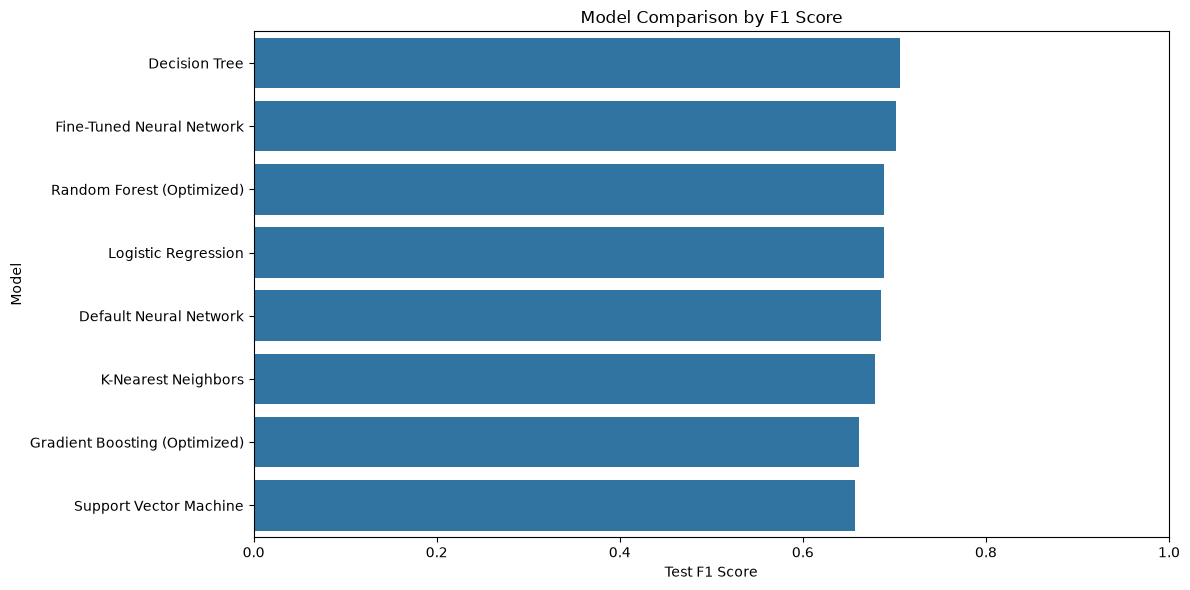


Best model by test F1 score: Decision Tree

Classification Report:
              precision    recall  f1-score   support

     On Time       0.56      0.52      0.54       887
 Not On Time       0.69      0.72      0.71      1313

    accuracy                           0.64      2200
   macro avg       0.62      0.62      0.62      2200
weighted avg       0.64      0.64      0.64      2200



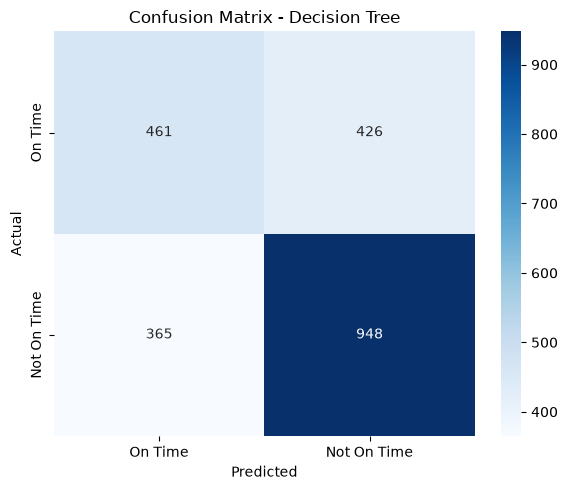

In [13]:
# ------------------------------------------------------------
# 11. VISUALIZE MODEL PERFORMANCE
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="F1_Score",
    y="Model"
)

plt.title("Model Comparison by F1 Score")
plt.xlabel("Test F1 Score")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. BEST MODEL REPORT
# ------------------------------------------------------------

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

print("\nBest model by test F1 score:", best_model_name)

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_predictions,
    target_names=["On Time", "Not On Time"],
    zero_division=0
))

cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["On Time", "Not On Time"],
    yticklabels=["On Time", "Not On Time"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


In [14]:
# ------------------------------------------------------------
# 13. SAVE RESULTS AND MODELS
# ------------------------------------------------------------

results_df.to_csv(
    "E_Commerce_Model_Comparison.csv",
    index=False
)

joblib.dump(
    best_model,
    "E_Commerce_Best_Model.joblib"
)

joblib.dump(
    trained_models,
    "E_Commerce_All_Trained_Models.joblib"
)

print("\nSaved files:")
print("1. E_Commerce_Model_Comparison.csv")
print("2. E_Commerce_Best_Model.joblib")
print("3. E_Commerce_All_Trained_Models.joblib")

print("\nMODEL SELECTION AND TRAINING COMPLETED!")



Saved files:
1. E_Commerce_Model_Comparison.csv
2. E_Commerce_Best_Model.joblib
3. E_Commerce_All_Trained_Models.joblib

MODEL SELECTION AND TRAINING COMPLETED!


Evaluation of Model and optimization


In [19]:
# ============================================================
# E-COMMERCE DELIVERY PERFORMANCE ANALYSIS
# MODEL EVALUATION AND OPTIMIZATION
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

In [20]:
# ------------------------------------------------------------
# 1. LOAD DATASET
# ------------------------------------------------------------

from pathlib import Path
import pandas as pd
import numpy as np

# Locate the dataset
file_path = Path("E_Commerce (1).csv")

if not file_path.exists():
    alternatives = [
        Path("E_Commerce.csv"),
        Path("E_Commerce_Cleaned.csv"),
        Path("E_Commerce_Preprocessed.csv")
    ]

    file_path = next(
        (p for p in alternatives if p.exists()),
        None
    )

if file_path is None:
    raise FileNotFoundError(
        "Dataset not found. Place the E-Commerce CSV file "
        "in the same folder as this notebook, or update file_path."
    )

# Load dataset
df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset file:", file_path)
print("Original dataset shape:", df.shape)

# Define target column
target = "Reached.on.Time_Y.N"

if target not in df.columns:
    raise ValueError(
        f"Target column '{target}' not found.\n"
        f"Available columns: {df.columns.tolist()}"
    )

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Convert target to numeric
df[target] = pd.to_numeric(
    df[target],
    errors="coerce"
)

# Remove missing or invalid target values
df = df.dropna(subset=[target]).copy()
df = df[df[target].isin([0, 1])].copy()
df[target] = df[target].astype(int)

# Separate features and target
X = df.drop(columns=[target]).copy()
y = df[target].copy()

# Exclude identifier from prediction
if "ID" in X.columns:
    X = X.drop(columns=["ID"])

# Replace infinite values with missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Display dataset information
print("\nData Cleaning Completed Successfully!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget class distribution:")
print(y.value_counts().sort_index())
print("\nTarget class proportions:")
print(y.value_counts(normalize=True).sort_index().round(4))
print("\nMissing values in features:", X.isna().sum().sum())

Dataset loaded successfully!
Dataset file: E_Commerce (1).csv
Original dataset shape: (10999, 12)

Data Cleaning Completed Successfully!
Features shape: (10999, 10)
Target shape: (10999,)

Target class distribution:
Reached.on.Time_Y.N
0    4436
1    6563
Name: count, dtype: int64

Target class proportions:
Reached.on.Time_Y.N
0    0.4033
1    0.5967
Name: proportion, dtype: float64

Missing values in features: 0


In [18]:
# ------------------------------------------------------------
# 3. DEFINE EIGHT MODELS
# ------------------------------------------------------------

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "Default Neural Network": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=300,
        early_stopping=True,
        random_state=42
    ),

    "Fine-Tuned Neural Network": MLPClassifier(
        hidden_layer_sizes=(100, 50),
        activation="relu",
        alpha=0.001,
        learning_rate_init=0.001,
        max_iter=300,
        early_stopping=True,
        random_state=42
    )
}

print("All eight models defined successfully!")

for model_name in models:
    print("-", model_name)

All eight models defined successfully!
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- KNN
- SVM
- Default Neural Network
- Fine-Tuned Neural Network


In [22]:
# ------------------------------------------------------------
# 4. HYPERPARAMETER SEARCH SPACES
# ------------------------------------------------------------

param_spaces = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10]
    },

    "Decision Tree": {
        "model__max_depth": [5, 10, 20, None],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [10, 20, None],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", 0.8]
    },

    "Gradient Boosting": {
        "model__n_estimators": [100, 150, 200],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [2, 3],
        "model__subsample": [0.8, 1.0]
    },

    "KNN": {
        "model__n_neighbors": [3, 5, 7, 11],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]
    },

    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["rbf", "linear"],
        "model__gamma": ["scale", "auto"]
    },

    "Fine-Tuned Neural Network": {
        "model__hidden_layer_sizes": [
            (32,),
            (64, 32),
            (100, 50)
        ],
        "model__activation": ["relu", "tanh"],
        "model__alpha": [0.0001, 0.001, 0.01],
        "model__learning_rate_init": [0.001, 0.01]
    }
}

print("Hyperparameter search spaces defined successfully!")

for model_name, parameters in param_spaces.items():
    print(f"\n{model_name}")
    for parameter, values in parameters.items():
        print(f"  {parameter}: {values}")

Hyperparameter search spaces defined successfully!

Logistic Regression
  model__C: [0.01, 0.1, 1, 10]

Decision Tree
  model__max_depth: [5, 10, 20, None]
  model__min_samples_split: [2, 5, 10]
  model__min_samples_leaf: [1, 2, 4]

Random Forest
  model__n_estimators: [100, 200, 300]
  model__max_depth: [10, 20, None]
  model__min_samples_split: [2, 5, 10]
  model__min_samples_leaf: [1, 2, 4]
  model__max_features: ['sqrt', 0.8]

Gradient Boosting
  model__n_estimators: [100, 150, 200]
  model__learning_rate: [0.03, 0.05, 0.1]
  model__max_depth: [2, 3]
  model__subsample: [0.8, 1.0]

KNN
  model__n_neighbors: [3, 5, 7, 11]
  model__weights: ['uniform', 'distance']
  model__p: [1, 2]

SVM
  model__C: [0.1, 1, 10]
  model__kernel: ['rbf', 'linear']
  model__gamma: ['scale', 'auto']

Fine-Tuned Neural Network
  model__hidden_layer_sizes: [(32,), (64, 32), (100, 50)]
  model__activation: ['relu', 'tanh']
  model__alpha: [0.0001, 0.001, 0.01]
  model__learning_rate_init: [0.001, 0.01]


In [10]:
# ------------------------------------------------------------
# 5. TRAIN, EVALUATE AND OPTIMIZE ALL MODELS
# ------------------------------------------------------------

trained_models = {}
results = {}

for name, estimator in models.items():

    print("\n" + "=" * 65)
    print("Evaluating:", name)
    print("=" * 65)

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    if name in param_spaces:
        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=param_spaces[name],
            n_iter=5,
            scoring="f1",
            cv=cv,
            random_state=42,
            n_jobs=-1,
            refit=True,
            error_score="raise"
        )

        search.fit(X_train, y_train)
        best_model = search.best_estimator_

        print("Best CV F1:", round(search.best_score_, 4))
        print("Best parameters:", search.best_params_)

    else:
        best_model = pipeline.fit(X_train, y_train)

    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]

    results[name] = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC AUC": roc_auc_score(y_test, y_prob)
    }

    trained_models[name] = best_model

    print("Test Accuracy :", round(results[name]["Accuracy"], 4))
    print("Test Precision:", round(results[name]["Precision"], 4))
    print("Test Recall   :", round(results[name]["Recall"], 4))
    print("Test F1 Score :", round(results[name]["F1 Score"], 4))
    print("Test ROC AUC  :", round(results[name]["ROC AUC"], 4))



Evaluating: Logistic Regression
Best CV F1: 0.7009
Best parameters: {'model__C': 0.01}
Test Accuracy : 0.6441
Test Precision: 0.7045
Test Recall   : 0.6954
Test F1 Score : 0.6999
Test ROC AUC  : 0.7232

Evaluating: Decision Tree
Best CV F1: 0.7047
Best parameters: {'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_depth': 20}
Test Accuracy : 0.6436
Test Precision: 0.7094
Test Recall   : 0.6824
Test F1 Score : 0.6957
Test ROC AUC  : 0.6988

Evaluating: Random Forest
Best CV F1: 0.6834
Best parameters: {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 20}
Test Accuracy : 0.6623
Test Precision: 0.7629
Test Recall   : 0.6299
Test F1 Score : 0.69
Test ROC AUC  : 0.7336

Evaluating: Gradient Boosting
Best CV F1: 0.6755
Best parameters: {'model__subsample': 0.8, 'model__n_estimators': 100, 'model__max_depth': 3, 'model__learning_rate': 0.1}
Test Accuracy : 0.675
Test Precision: 

In [21]:
# ------------------------------------------------------------
# 6. MODEL COMPARISON TABLE
# ------------------------------------------------------------

results_df = pd.DataFrame(list(results.values()))

results_df = results_df.sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

print("\nMODEL EVALUATION COMPARISON")
display(results_df.round(4))

results_df.to_csv(
    "E_Commerce_Model_Evaluation.csv",
    index=False
)



MODEL EVALUATION COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Fine-Tuned Neural Network,0.6459,0.7051,0.6992,0.7021,0.7291
1,Logistic Regression,0.6441,0.7045,0.6954,0.6999,0.7232
2,Decision Tree,0.6436,0.7094,0.6824,0.6957,0.6988
3,Random Forest,0.6623,0.7629,0.6299,0.6900,0.7336
4,KNN,0.6509,0.7343,0.6504,0.6898,0.7222
5,Default Neural Network,0.6573,0.7576,0.6260,0.6856,0.7317
6,SVM,0.6641,0.7781,0.6116,0.6849,0.7371
7,Gradient Boosting,0.6750,0.8738,0.5324,0.6616,0.7466


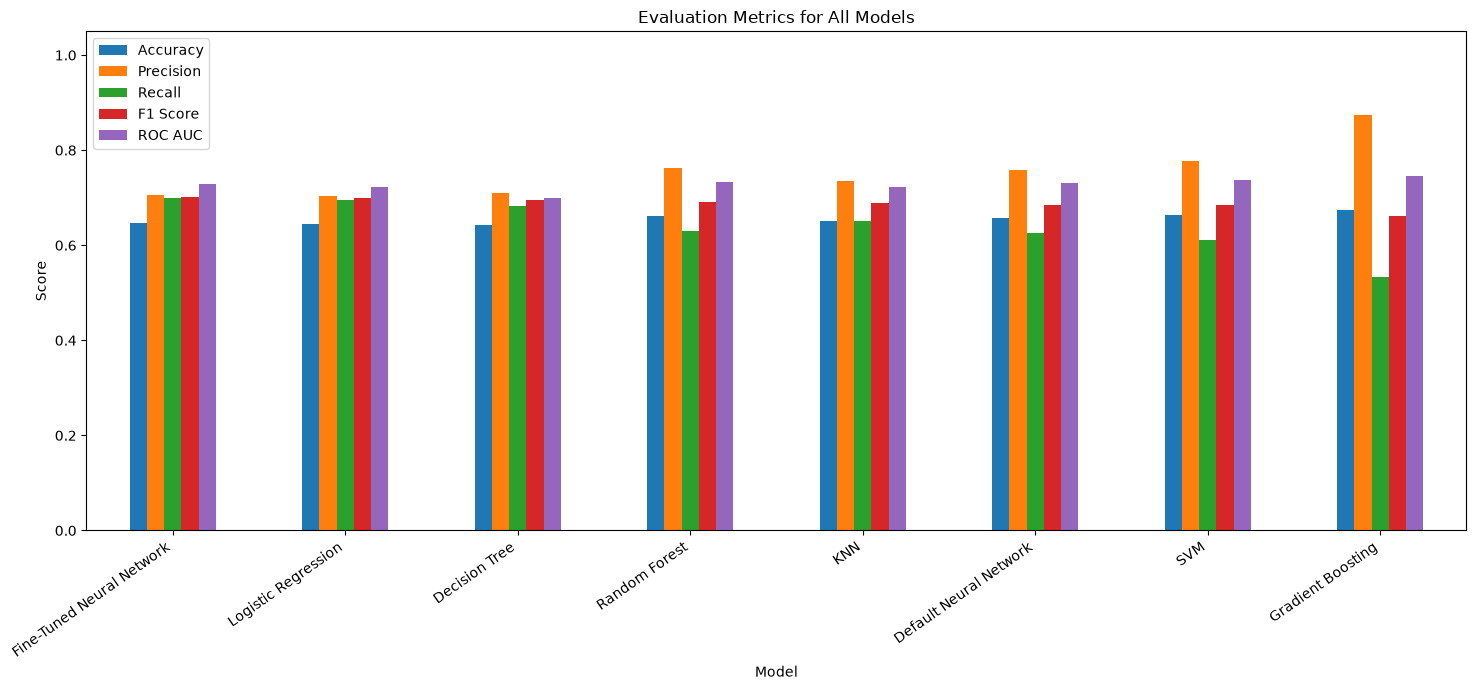

In [22]:
# ------------------------------------------------------------
# 7. COMPARE MODEL METRICS VISUALLY
# ------------------------------------------------------------

metric_cols = [
    "Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"
]

plot_df = results_df.set_index("Model")[metric_cols]

plot_df.plot(
    kind="bar",
    figsize=(15, 7)
)

plt.title("Evaluation Metrics for All Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


In [23]:
# ------------------------------------------------------------
# 8. SELECT THE BEST MODEL
# ------------------------------------------------------------

best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

print("\nBest model based on test F1 Score:", best_name)

best_pred = best_model.predict(X_test)
best_prob = best_model.predict_proba(X_test)[:, 1]



Best model based on test F1 Score: Fine-Tuned Neural Network


In [24]:
# ------------------------------------------------------------
# 9. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_pred,
    labels=[0, 1],
    target_names=["On Time", "Not On Time"],
    zero_division=0
))



Classification Report:
              precision    recall  f1-score   support

     On Time       0.56      0.57      0.56       887
 Not On Time       0.71      0.70      0.70      1313

    accuracy                           0.65      2200
   macro avg       0.63      0.63      0.63      2200
weighted avg       0.65      0.65      0.65      2200



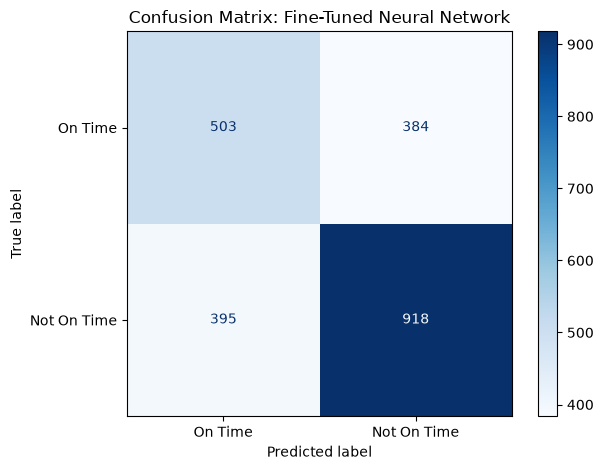

In [25]:
# ------------------------------------------------------------
# 10. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(y_test, best_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["On Time", "Not On Time"]
).plot(cmap="Blues", values_format="d")

plt.title(f"Confusion Matrix: {best_name}")
plt.tight_layout()
plt.show()

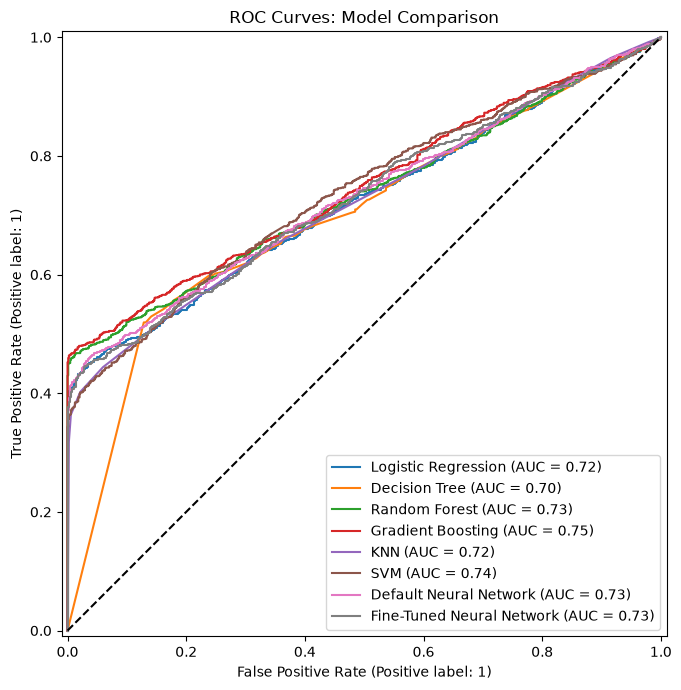

In [26]:
# ------------------------------------------------------------
# 11. ROC CURVES
# ------------------------------------------------------------

plt.figure(figsize=(9, 7))

for name, model in trained_models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=plt.gca()
    )

plt.plot([0, 1], [0, 1], "k--")
plt.title("ROC Curves: Model Comparison")
plt.tight_layout()
plt.show()

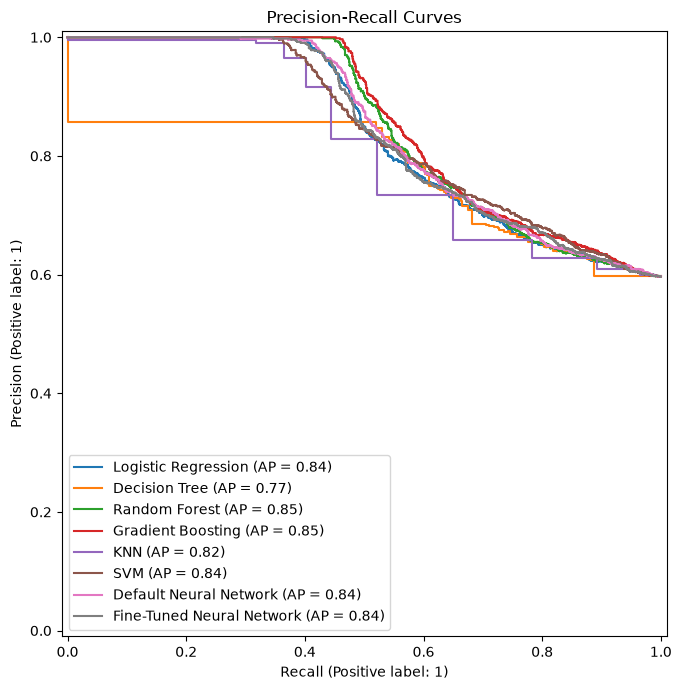

In [27]:
# ------------------------------------------------------------
# 12. PRECISION-RECALL CURVES
# ------------------------------------------------------------

plt.figure(figsize=(9, 7))

for name, model in trained_models.items():
    PrecisionRecallDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=plt.gca()
    )

plt.title("Precision-Recall Curves")
plt.tight_layout()
plt.show()


In [28]:
# ------------------------------------------------------------
# 13. SAVE BEST MODEL AND ALL MODELS
# ------------------------------------------------------------

joblib.dump(
    best_model,
    "E_Commerce_Optimized_Best_Model.joblib"
)

joblib.dump(
    trained_models,
    "E_Commerce_Evaluated_Models.joblib"
)

print("\nSaved successfully:")
print("1. E_Commerce_Model_Evaluation.csv")
print("2. E_Commerce_Optimized_Best_Model.joblib")
print("3. E_Commerce_Evaluated_Models.joblib")

print("\nMODEL EVALUATION AND OPTIMIZATION COMPLETED!")



Saved successfully:
1. E_Commerce_Model_Evaluation.csv
2. E_Commerce_Optimized_Best_Model.joblib
3. E_Commerce_Evaluated_Models.joblib

MODEL EVALUATION AND OPTIMIZATION COMPLETED!


In [1]:
%pip install joblib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import joblib

# 1. Load your dataset
df = pd.read_csv('E_Commerce.csv')

# 2. Separate features and target
X = df.drop(columns=['ID', 'Reached.on.Time_Y.N'])
y = df['Reached.on.Time_Y.N']

# 3. Identify categorical columns for text handling
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()

# 4. Create preprocessing and model pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ],
    remainder='passthrough'
)

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# 5. Train/Test Split and Train the model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model_pipeline.fit(X_train, y_train)

# 6. Save the trained model pipeline successfully!
joblib.dump(model_pipeline, 'model.pkl')

print("✅ Success! Model trained and saved as 'model.pkl'.")

✅ Success! Model trained and saved as 'model.pkl'.


In [10]:
joblib.dump(model_pipeline, "model.pkl")
print("Saved trained pipeline to model.pkl")

Saved trained pipeline to model.pkl


In [11]:
ecommerce-app/
│
├── app.py              # Main Streamlit application file
├── model.pkl           # Your saved machine learning model
└── requirements.txt    # List of required python libraries

SyntaxError: invalid character '│' (U+2502) (472105697.py, line 2)